# 02 Peak Hours

## From 01

- 27 series: NO₂ 15 stations, PM2.5 12 (mc027, mc145, mc282 NO₂ only)
- Coverage 98.5–99.9%
- Hour = hour start (shifted −1h)
- `fireworks` flag: 31 Dec 18:00 – 1 Jan 06:00
- Max NO₂ 121, max PM2.5 276 µg/m³
- Top 10 PM2.5 hours all New Year, 6 stations in the same hour
- Top 10 NO₂ hours all March, 18:00–21:00, mostly traffic
- Values are integers

In [16]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")

# One colour system for the whole notebook.
# Hue = pollutant. Lightness = above or below the limit. Blue/orange is CVD safe.
COLOUR = {"no2": "#4c72b0", "pm2": "#dd8452"}       # full: above the limit
PALE   = {"no2": "#b8c6de", "pm2": "#f0cab5"}       # pale: below
CMAP   = {"no2": "mako_r", "pm2": "flare"}          # heatmap ramps, same hues
CURRENT = {"no2": 40, "pm2": 25}        # 2008 directive, in force now

LIMIT = {"no2": 20, "pm2": 10}      # EU 2030 annual mean
WHO   = {"no2": 10, "pm2": 5}

# $_2$ renders the subscript. The plain ₂ character draws as a box in figures.
LABEL = {
    "no2": "NO$_2$ · mainly traffic exhaust · airways",
    "pm2": "PM2.5 · fine particles · heart and blood vessels",
}

# Street and locality. Addresses from the SenMVKU monthly reports.
NAME = {
    "mc010": "Amrumer Str., Wedding",
    "mc027": "Schichauweg, Marienfelde",
    "mc032": "Grunewald, Charlottenburg-Wilmersdorf",
    "mc042": "Nansenstr., Neukölln",
    "mc077": "Buch, Pankow",
    "mc085": "Friedrichshagen, Treptow-Köpenick",
    "mc117": "Schildhornstr., Steglitz",
    "mc124": "Mariendorfer Damm, Mariendorf",
    "mc144": "Silbersteinstr., Neukölln",
    "mc145": "Frohnau, Reinickendorf",
    "mc171": "Brückenstr., Mitte",
    "mc174": "Frankfurter Allee, Friedrichshain",
    "mc190": "Leipziger Str., Mitte",
    "mc221": "Karl-Marx-Str., Neukölln",
    "mc282": "Karlshorst, Lichtenberg",
}

# Station type, from the BLUME station groups
TYPE = {
    "mc010": "background", "mc042": "background",
    "mc171": "background", "mc282": "background",
    "mc027": "suburb", "mc032": "suburb", "mc077": "suburb",
    "mc085": "suburb", "mc145": "suburb",
    "mc117": "traffic", "mc124": "traffic", "mc144": "traffic",
    "mc174": "traffic", "mc190": "traffic", "mc221": "traffic",
}

# Cleaned table from 01. Drops and fireworks flag already applied.
# CSV stores the offset as text, so parse to UTC then convert, as in 01.
ROOT = Path.cwd().parent
df = pd.read_csv(ROOT / "data" / "processed" / "hourly.csv")
df["datetime"] = pd.to_datetime(df["datetime"], utc=True).dt.tz_convert("Europe/Berlin")

print(df.shape)
print(df["core"].value_counts())

(236180, 7)
core
no2    131288
pm2    104892
Name: count, dtype: int64


In [17]:
# Average by hour of day: every 07:00 of the year becomes one number.
# Averages, not single peaks. Is 07:00 reliably bad?
# mean() skips nulls.
mat = (
    df.groupby(["core", "station", df["datetime"].dt.hour])["value"]
    .mean()
    .rename("mean")
    .reset_index()
    .rename(columns={"datetime": "hour"})      # the hour key inherits the source column name
)

mat.head()

,core,station,hour,mean
0,no2,mc010,0,19.435616
1,no2,mc010,1,17.585165
2,no2,mc010,2,16.200549
3,no2,mc010,3,15.882192
4,no2,mc010,4,16.463014


In [18]:
# 15 NO₂ × 24 h = 360, 12 PM2.5 × 24 = 288. Each station should show 24.
# size() counts nulls too, so totals run above the valid hours in 01.
print(mat.groupby("core").size())
print(mat.groupby(["core", "station"]).size().value_counts())

core
no2    360
pm2    288
dtype: int64
24    27
Name: count, dtype: int64


In [19]:
# Top 10 % of station-hours. Cutoff = 90th percentile within each pollutant.
# Separate cutoffs because PM2.5 sits lower. One shared cutoff would select only NO₂.
# H1: do the top cells cluster at a few stations?
for core, g in mat.groupby("core"):
    cut = g["mean"].quantile(0.90)             # the threshold
    top = g[g["mean"] >= cut]                  # cells at or above it
    print(
        core,
        "| cutoff", round(cut, 1),             # µg/m³
        "| cells", len(top), "of", len(g),     # ~36 of 360, ~29 of 288
        "| stations", top["station"].nunique(),  # few = H1 holds
        "| hours", top["hour"].nunique(),
    )

no2 | cutoff 27.4 | cells 36 of 360 | stations 5 | hours 12
pm2 | cutoff 14.2 | cells 29 of 288 | stations 4 | hours 12


In [20]:
# Which stations hold those cells, and the annual means behind them.
# A top decile always has members. The spread shows whether it matters.
for core, g in mat.groupby("core"):
    cut = g["mean"].quantile(0.90)
    print(core, g[g["mean"] >= cut]["station"].value_counts().to_dict())

# Station annual means, best to worst
print(df.groupby(["core", "station"])["value"].mean().round(1))

no2 {'mc124': 11, 'mc144': 10, 'mc190': 7, 'mc221': 5, 'mc174': 3}
pm2 {'mc124': 9, 'mc174': 8, 'mc144': 7, 'mc221': 5}
core  station
no2   mc010      18.0
      mc027       8.4
      mc032       7.8
      mc042      15.2
      mc077       9.2
      mc085       7.8
      mc117      16.2
      mc124      26.3
      mc144      25.7
      mc145       7.6
      mc171      15.2
      mc174      23.7
      mc190      24.4
      mc221      22.4
      mc282      12.8
pm2   mc010      10.9
      mc032       8.2
      mc042      12.0
      mc077       9.2
      mc085       9.4
      mc117      11.0
      mc124      13.6
      mc144      13.4
      mc171      11.7
      mc174      13.6
      mc190      12.5
      mc221      13.1
Name: value, dtype: float64


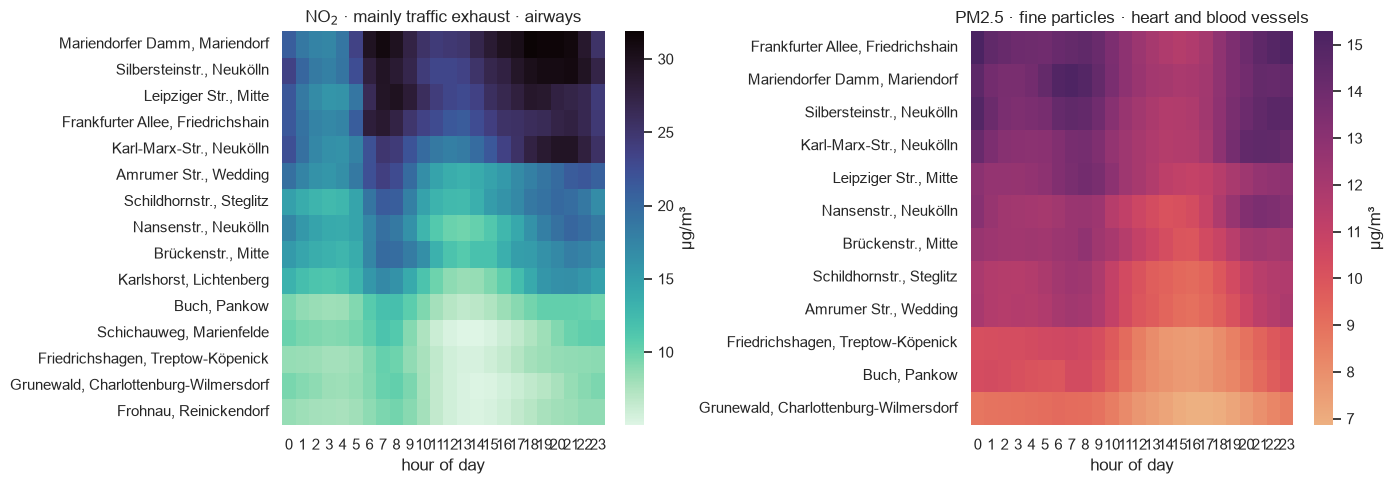

In [21]:
# Station × hour, one panel per pollutant. Rows worst to best.
# Separate scales because levels differ. Ramp follows the pollutant colour.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, core in zip(axes, ["no2", "pm2"]):
    p = mat[mat["core"] == core].pivot(index="station", columns="hour", values="mean")
    p = p.loc[p.mean(axis=1).sort_values(ascending=False).index]
    p.index = p.index.map(NAME)                  # station codes to street names
    sns.heatmap(p, ax=ax, cmap=CMAP[core], cbar_kws={"label": "µg/m³"})
    ax.set_title(LABEL[core])
    ax.set_xlabel("hour of day")
    ax.set_ylabel("")

plt.tight_layout()
(ROOT / "figures").mkdir(exist_ok=True)
plt.savefig(ROOT / "figures" / "02_heatmap.png", dpi=150)

<StringArray>
[]
Length: 0, dtype: str


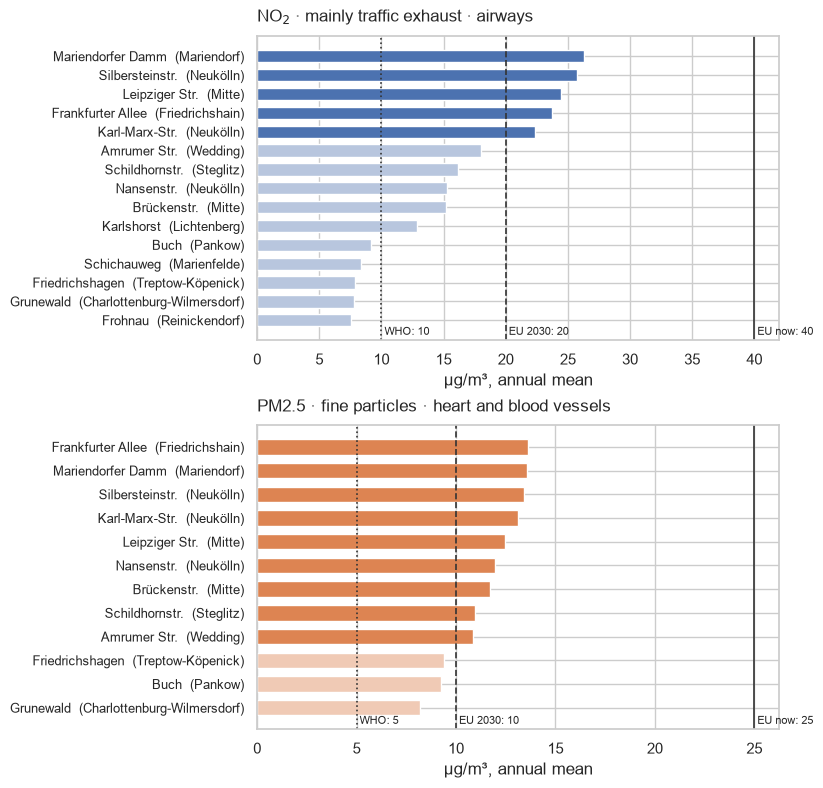

In [22]:
# Annual mean per station, one panel per pollutant.
# Three reference lines: current EU limit, EU 2030, WHO.
# Full colour above the 2030 limit, pale below.

ann = df.groupby(["core", "station"])["value"].mean().reset_index()
ann["name"] = ann["station"].map(NAME)
print(ann[ann["name"].isna()]["station"].unique())      # should be empty

fig, axes = plt.subplots(2, 1, figsize=(9, 9))

for ax, core in zip(axes, ["no2", "pm2"]):
    g = ann[ann["core"] == core].sort_values("value", ascending=False)
    colours = [COLOUR[core] if v > LIMIT[core] else PALE[core] for v in g["value"]]

    ax.barh(g["name"], g["value"], color=colours, height=0.65)

    for v, style, name in [(CURRENT[core], "-", "EU now"),
                           (LIMIT[core], "--", "EU 2030"),
                           (WHO[core], ":", "WHO")]:
        ax.axvline(v, color="#333333", lw=1.2, ls=style)
        ax.text(v, 0.01, f" {name}: {v}", fontsize=8,
                transform=ax.get_xaxis_transform(), ha="left", va="bottom")

    ax.invert_yaxis()
    ax.set_title(LABEL[core], pad=10, loc="left")
    ax.set_xlabel("µg/m³, annual mean")

    labels = [f"{n.split(', ')[0]}  ({n.split(', ')[1]})" if ", " in n else n
              for n in g["name"]]
    ax.set_yticks(range(len(g)))
    ax.set_yticklabels(labels, fontsize=9)

plt.subplots_adjust(left=0.38, right=0.96, hspace=0.28)
plt.savefig(ROOT / "figures" / "02_station_ranking.png", dpi=150, pad_inches=0.3)

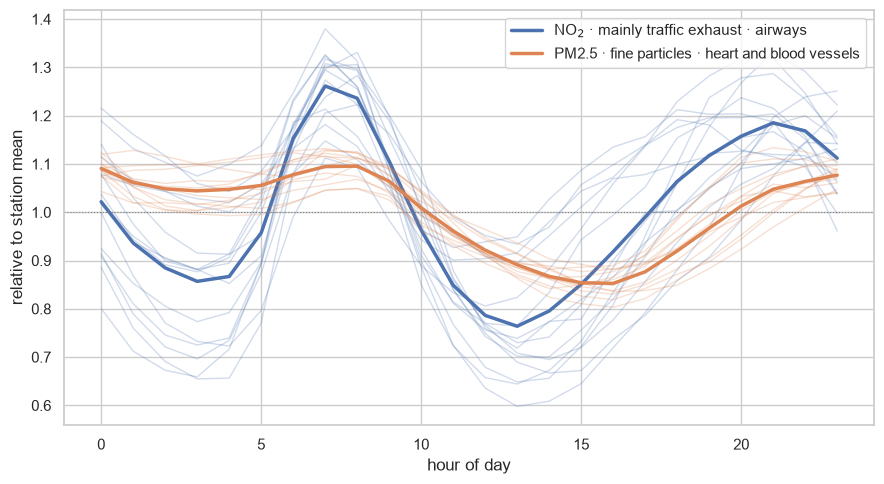

In [23]:
# Each station-hour as a share of that station's own yearly mean.
# 1.0 = typical for that station. Removes the level difference so the
# daily shape of the two pollutants can be compared directly.
rel = mat.copy()
rel["rel"] = rel["mean"] / rel.groupby(["core", "station"])["mean"].transform("mean")

fig, ax = plt.subplots(figsize=(9, 5))

for core in ["no2", "pm2"]:
    g = rel[rel["core"] == core]
    for st, s in g.groupby("station"):
        ax.plot(s["hour"], s["rel"], color=COLOUR[core], alpha=0.25, lw=1, label="_nolegend_")
    ax.plot(g.groupby("hour")["rel"].mean(), color=COLOUR[core], lw=2.5, label=LABEL[core])

ax.axhline(1, color="grey", lw=0.8, ls=":")
ax.set_xlabel("hour of day")
ax.set_ylabel("relative to station mean")
ax.legend()

plt.tight_layout()
plt.savefig(ROOT / "figures" / "02_daily_cycle_relative.png", dpi=150)

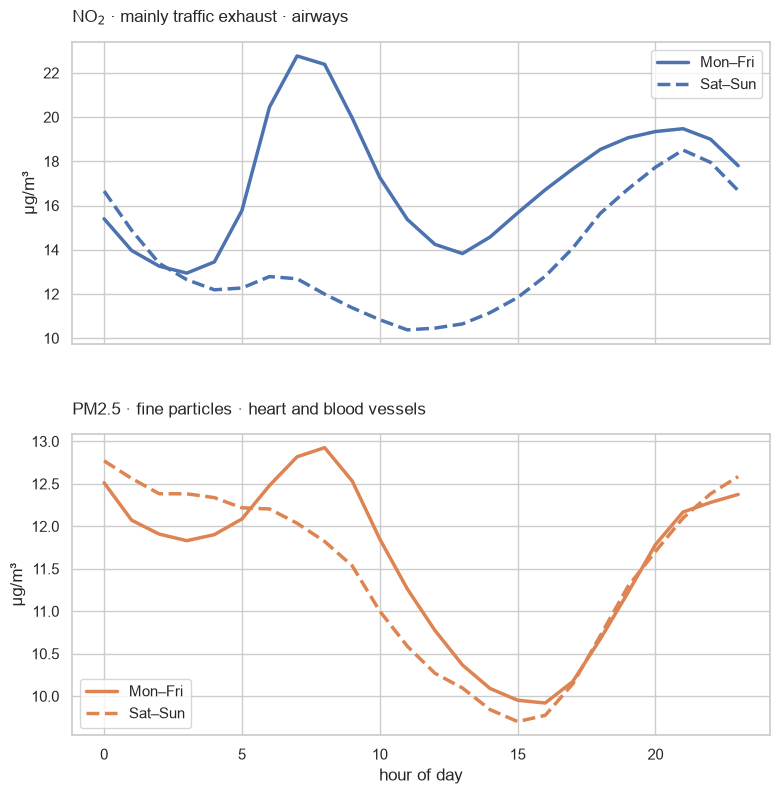

In [24]:
# Weekday against weekend. NO₂ is traffic, so it should drop. PM2.5 is regional,
# so it should not. Same hypothesis as the daily cycle, independent evidence.
d = df.copy()
d["weekend"] = d["datetime"].dt.dayofweek >= 5
d["hour"] = d["datetime"].dt.hour
d["type"] = d["station"].map(TYPE)

fig, axes = plt.subplots(2, 1, figsize=(9, 9), sharex=True)

for ax, core in zip(axes, ["no2", "pm2"]):
    g = d[d["core"] == core].groupby(["weekend", "hour"])["value"].mean().unstack(0)
    ax.plot(g.index, g[False], color=COLOUR[core], lw=2.5, label="Mon–Fri")
    ax.plot(g.index, g[True], color=COLOUR[core], lw=2.5, ls="--", label="Sat–Sun")
    ax.set_title(LABEL[core], pad=14, loc="left")
    ax.set_ylabel("µg/m³")
    ax.legend()

axes[1].set_xlabel("hour of day")
plt.subplots_adjust(hspace=0.3)
plt.savefig(ROOT / "figures" / "02_weekday_weekend.png", dpi=150, pad_inches=0.4)

In [25]:
# Weekend drop per traffic station. How much of each street's NO₂ is its own traffic.
d = df[(df["core"] == "no2") & (df["station"].map(TYPE) == "traffic")].copy()
d["weekend"] = d["datetime"].dt.dayofweek >= 5

g = d.groupby(["station", "weekend"])["value"].mean().unstack()
g["drop_pct"] = ((g[False] - g[True]) / g[False] * 100).round(1)
g.index = g.index.map(NAME)
print(g.sort_values("drop_pct", ascending=False))

weekend                                False       True  drop_pct
station                                                          
Mariendorfer Damm, Mariendorf      28.336803  21.214515      25.1
Frankfurter Allee, Friedrichshain  25.400449  19.419006      23.5
Schildhornstr., Steglitz           17.255244  13.543705      21.5
Leipziger Str., Mitte              25.936579  20.662791      20.3
Silbersteinstr., Neukölln          27.216709  22.014039      19.1
Karl-Marx-Str., Neukölln           23.415973  19.709302      15.8


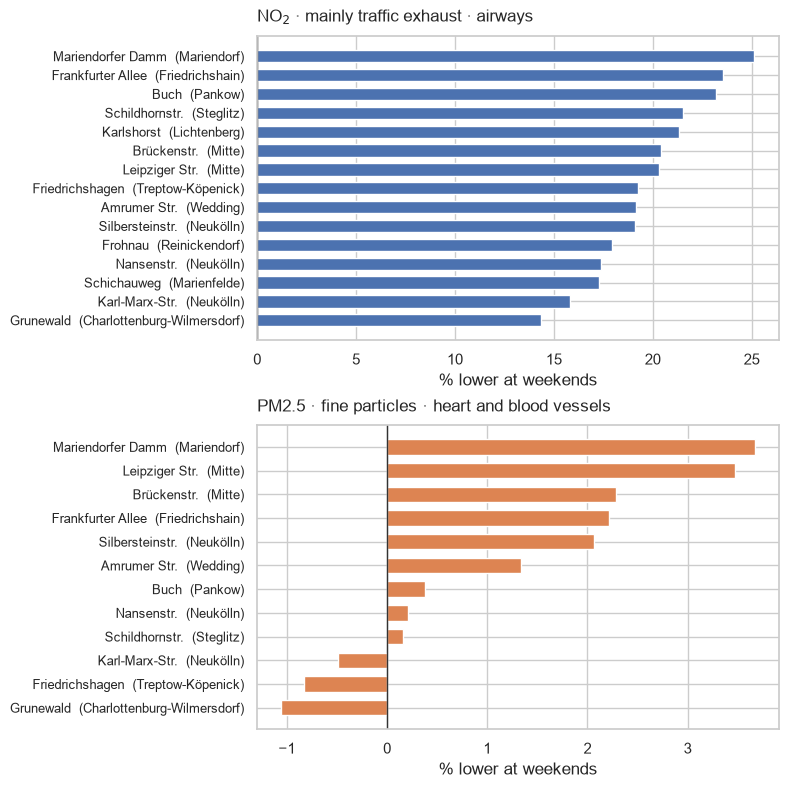

In [26]:
# Weekend drop per station. How much of each street's load is its own weekday traffic.
# NO₂ should fall at traffic stations. PM2.5 should not.
d = df.copy()
d["weekend"] = d["datetime"].dt.dayofweek >= 5

drop = (d.groupby(["core", "station", "weekend"])["value"].mean()
          .unstack("weekend")
          .assign(pct=lambda x: (x[False] - x[True]) / x[False] * 100)
          .reset_index())
drop["name"] = drop["station"].map(NAME)
drop["type"] = drop["station"].map(TYPE)

fig, axes = plt.subplots(2, 1, figsize=(9, 9))

for ax, core in zip(axes, ["no2", "pm2"]):
    g = drop[drop["core"] == core].sort_values("pct", ascending=False)
    colours = [COLOUR[core] if t == "traffic" else PALE[core] for t in g["type"]]

    ax.barh(g["name"], g["pct"], color=COLOUR[core], height=0.65)
    ax.axvline(0, color="#333333", lw=1)
    ax.invert_yaxis()
    ax.set_title(LABEL[core], pad=10, loc="left")
    ax.set_xlabel("% lower at weekends")

    labels = [f"{n.split(', ')[0]}  ({n.split(', ')[1]})" if ", " in n else n
              for n in g["name"]]
    ax.set_yticks(range(len(g)))
    ax.set_yticklabels(labels, fontsize=9)

plt.subplots_adjust(left=0.38, right=0.96, hspace=0.28)
plt.savefig(ROOT / "figures" / "02_weekend_drop.png", dpi=150, pad_inches=0.3)

In [27]:
# How much of a traffic station's NO₂ is above the suburb baseline, by day type.
# If the increment holds steady at weekends, the weekend drop is regional, not local.
d = df[df["core"] == "no2"].copy()
d["weekend"] = d["datetime"].dt.dayofweek >= 5
d["type"] = d["station"].map(TYPE)

base = d[d["type"] == "suburb"].groupby("weekend")["value"].mean()
traf = d[d["type"] == "traffic"].groupby(["station", "weekend"])["value"].mean()

inc = (traf - base).unstack()
inc.columns = ["weekday", "weekend"]
inc["change_pct"] = ((inc["weekday"] - inc["weekend"]) / inc["weekday"] * 100).round(1)
inc.index = inc.index.map(NAME)
print(inc.round(1).sort_values("change_pct", ascending=False))

                                   weekday  weekend  change_pct
station                                                        
Mariendorfer Damm, Mariendorf         19.7     14.2        28.0
Frankfurter Allee, Friedrichshain     16.8     12.4        26.1
Schildhornstr., Steglitz               8.7      6.5        24.4
Leipziger Str., Mitte                 17.3     13.7        21.2
Silbersteinstr., Neukölln             18.6     15.0        19.4
Karl-Marx-Str., Neukölln              14.8     12.7        14.2


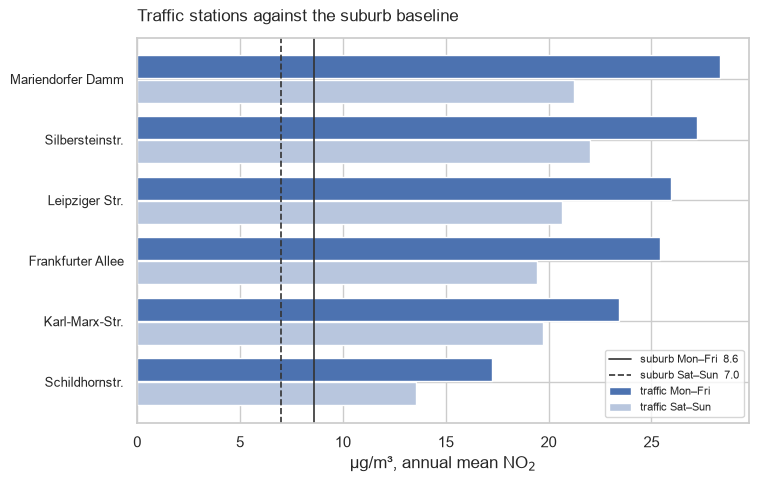

In [28]:
# Traffic stations against the suburb baseline, weekday and weekend.
# Bar = absolute level. Vertical lines = suburb mean for each day type.
# The increment is the distance from the line to the bar.
traf_abs = (d[d["type"] == "traffic"]
            .groupby(["station", "weekend"])["value"].mean().unstack())
traf_abs.columns = ["weekday", "weekend"]
traf_abs.index = traf_abs.index.map(NAME)

g = traf_abs.sort_values("weekday", ascending=False)
y = range(len(g))

fig, ax = plt.subplots(figsize=(9, 5))

ax.barh([i - 0.2 for i in y], g["weekday"], height=0.38,
        color=COLOUR["no2"], label="traffic Mon–Fri")
ax.barh([i + 0.2 for i in y], g["weekend"], height=0.38,
        color=PALE["no2"], label="traffic Sat–Sun")

ax.axvline(base[False], color="#333333", lw=1.2, ls="-",
           label=f"suburb Mon–Fri  {base[False]:.1f}")
ax.axvline(base[True], color="#333333", lw=1.2, ls="--",
           label=f"suburb Sat–Sun  {base[True]:.1f}")

ax.set_yticks(list(y))
ax.set_yticklabels([n.split(", ")[0] for n in g.index], fontsize=9)
ax.invert_yaxis()
ax.set_xlabel("µg/m³, annual mean NO$_2$")
ax.set_title("Traffic stations against the suburb baseline", pad=12, loc="left")
ax.legend(loc="lower right", fontsize=8)

plt.subplots_adjust(left=0.28, right=0.96)
plt.savefig(ROOT / "figures" / "02_traffic_increment.png", dpi=150, pad_inches=0.3)

## Findings

- H1 holds for NO₂: the top 10 % of station-hours sits at 5 of 15 stations, all traffic
- For PM2.5 the top decile also concentrates, 4 of 12, but the range is narrow
  enough that it means little
- Both vary by location, NO₂ far more. NO₂ spans 7.6 to 26.3 µg/m³, a factor
  of 3.5. PM2.5 spans 8.2 to 13.6, a factor of 1.7
- Even the cleanest station is above the WHO PM2.5 level of 5
- Compliance depends on the reference level applied. On annual means all 15
  stations are below the limits in force in 2025. Against the 2030 limits, 5 of 15
  NO₂ and 9 of 12 PM2.5 stations are above. Against the WHO levels, all 12 PM2.5
  stations are above. The 2030 limits apply from 2030, with compliance assessed
  from 2026
- NO₂ swings about 45 % from the 03:00 low to the 07:00 peak. PM2.5 stays within
  about 10 % all day
- Weekend NO₂ falls 14 to 25 % at every station, not only at traffic sites. Buch
  and Karlshorst drop more than Karl-Marx-Str., so the weekday effect is citywide
  rather than the measured street's own traffic
- Weekend PM2.5 moves under 4 % at any station
- The traffic increment over the suburb baseline falls 14 to 28 % at weekends,
  so part of the weekend drop is local street traffic rather than regional

## Decisions

- Hour-of-day means, not single peak hours. One extreme hour says nothing about
  whether an hour is reliably bad
- Cutoff per pollutant. PM2.5 sits lower and a shared cutoff would select only NO₂
- Relative chart normalised to each station mean, so the daily shape compares
  across different levels
- Three reference lines on the ranking: the limit in force in 2025, the 2030 limit,
  and the WHO level
- Linear scale throughout. Log would distort the spacing between threshold values

## Open

- Fireworks not excluded here. Effect checked in 03
- German public holidays counted as weekdays. About ten days a year, too few to
  change the weekend comparison
- Station type shown through the ranking order rather than its own figure
- Weekend NO₂ falls citywide, so the drop cannot be attributed to the measured
  street's own traffic. Separating local from regional would need the increment
  over the suburb stations, not done here
- Measuring height is published for 3 of 15 stations: 40 m, 35 m and 3 m. Two of
  the six traffic stations measure well above breathing height, and for the other
  four no height is published. The station ranking may not compare like with like